# 01: Exploratory Data Analysis

**Project:** Concept-Drift-Aware Credit-Card Fraud Detection Using Online, Imbalance-Aware Classical ML

This notebook explores the ULB credit-card dataset (the primary dataset in the synopsis) before any
modelling. Each section ends with what it means for the modelling choices made in the project.

| Section | Question |
|---|---|
| 1 | What does the data look like, and how clean is it? |
| 2 | How imbalanced is it? |
| 3 | Do fraud amounts differ from legitimate ones? |
| 4 | How is activity spread over time, and does fraud change over the 48 hours? |
| 5 | Which features separate fraud from legitimate transactions? |
| 6 | What does the injected drift change? |
| 7 | How large should evaluation batches be? |
| 8 | What does the synthetic drifting stream look like? |
| 9 | Summary: what the EDA means for the models |

**Data:** download `creditcard.csv` from https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud into `data/raw/`.

In [1]:
import sys
sys.path.insert(0, "..")  # so the project's src/ package can be imported

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data.loader import load_dataset, get_feature_columns
from src.data.drift_injection import inject_feature_swap
from src.viz.plots import apply_style, SINGLE_SERIES, MUTED, INK_SECONDARY

apply_style()
LEGIT, FRAUD = "#2a78d6", "#eb6834"  # fixed colours for the two classes in every chart below
pd.set_option("display.precision", 4)

raw = pd.read_csv("../data/raw/creditcard.csv")  # as downloaded
df = load_dataset("../data/raw/creditcard.csv")   # validated and time-sorted, as the models see it
features = get_feature_columns(df)

## 1. Overview and data quality

In [2]:
dupes = raw.duplicated()
overview = pd.Series({
    "rows": len(raw),
    "columns": raw.shape[1],
    "feature columns (V1-V28, Amount)": len(features),
    "missing values": int(raw.isna().sum().sum()),
    "exact duplicate rows": int(dupes.sum()),
    "  of which fraud": int(raw.loc[dupes, "Class"].sum()),
    "already sorted by Time": bool(raw["Time"].is_monotonic_increasing),
    "time span (hours)": round(raw["Time"].max() / 3600, 1),
})
overview.to_frame("value")

,value
rows,284807
columns,31
"feature columns (V1-V28, Amount)",29
missing values,0
exact duplicate rows,1081
of which fraud,19
already sorted by Time,True
time span (hours),48.0


In [3]:
raw[["Time", "V1", "V14", "Amount", "Class"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.4814e+04,47488.1460,0.0000,54201.5000,84692.0000,139320.5000,172792.0000
V1,284807.0,1.1752e-15,1.9587,-56.4075,-0.9204,0.0181,1.3156,2.4549
V14,284807.0,1.2135e-15,0.9586,-19.2143,-0.4256,0.0506,0.4931,10.5268
Amount,284807.0,8.8350e+01,250.1201,0.0000,5.6000,22.0000,77.1650,25691.1600
Class,284807.0,1.7275e-03,0.0415,0.0000,0.0000,0.0000,0.0000,1.0000


**Interpretation**

- 284,807 transactions over exactly 48 hours, 31 columns: `Time` (seconds since the first
  transaction), `V1`–`V28`, `Amount` and `Class`. `V1`–`V28` are PCA components released instead of
  the original (confidential) attributes, so they have no business meaning and are already centred
  near 0; `Time` and `Amount` are raw.
- **No missing values**, and the file is **already in time order**, which the streaming evaluation
  relies on.
- 1,081 rows (0.4%) are exact duplicates, 19 of them fraud. We keep them: repeated identical
  transactions are plausible (e.g. retried payments), and dropping rows would alter the stream the
  models see.
- `Time` is used only to order the stream, never as a model input: a model that learns "hour 26 of
  this file" wouldn't generalise to any other period.

## 2. Class imbalance

In [4]:
counts = raw["Class"].value_counts().rename({0: "legitimate", 1: "fraud"})
pd.DataFrame({"transactions": counts, "share (%)": (100 * counts / len(raw)).round(3)})

,transactions,share (%)
Class,,
legitimate,284315,99.827
fraud,492,0.173


In [5]:
always_legit_accuracy = 1 - raw["Class"].mean()
print(f"A model that always answers 'legitimate' is {always_legit_accuracy:.2%} accurate - and catches no fraud.")
print(f"A random ranking scores a PR-AUC of about {raw['Class'].mean():.4f} (the fraud rate).")
print(f"Legitimate transactions per fraud: {counts['legitimate'] / counts['fraud']:.0f}")

A model that always answers 'legitimate' is 99.83% accurate - and catches no fraud.
A random ranking scores a PR-AUC of about 0.0017 (the fraud rate).
Legitimate transactions per fraud: 578


**Interpretation**

- Only **492 of 284,807 transactions (0.173%) are fraud**, about 1 per 578 legitimate ones.
- A model that never flags fraud is **99.83% accurate**, so accuracy is useless here. This is why the
  project measures **PR-AUC**, **recall at 90% precision** and the **false-positive rate** (synopsis
  objective 1). For reference, a random ranking scores a PR-AUC of about 0.0017.
- Without correction, a model sees ~578 legitimate examples per fraud and can minimise its error by
  ignoring fraud. This motivates the imbalance handling compared in the project (class weights
  ≈ 578× per fraud, SMOTE, undersampling).

## 3. Transaction amounts

In [6]:
amount_stats = raw.groupby("Class")["Amount"].describe(percentiles=[.25, .5, .75, .95])
amount_stats.index = ["legitimate", "fraud"]
amount_stats.round(2)

,count,mean,std,min,25%,50%,75%,95%,max
legitimate,284315.0,88.29,250.11,0.0,5.65,22.00,77.05,364.41,25691.16
fraud,492.0,122.21,256.68,0.0,1.00,9.25,105.89,640.90,2125.87


In [7]:
by_class = raw.groupby("Class")["Amount"]
pd.DataFrame({
    "amount = 0 (%)": by_class.apply(lambda a: 100 * (a == 0).mean()),
    "amount <= 1 (%)": by_class.apply(lambda a: 100 * (a <= 1).mean()),
    "amount > 500 (%)": by_class.apply(lambda a: 100 * (a > 500).mean()),
}).rename(index={0: "legitimate", 1: "fraud"}).round(1)

,amount = 0 (%),amount <= 1 (%),amount > 500 (%)
Class,,,
legitimate,0.6,10.7,3.2
fraud,5.5,36.8,7.1


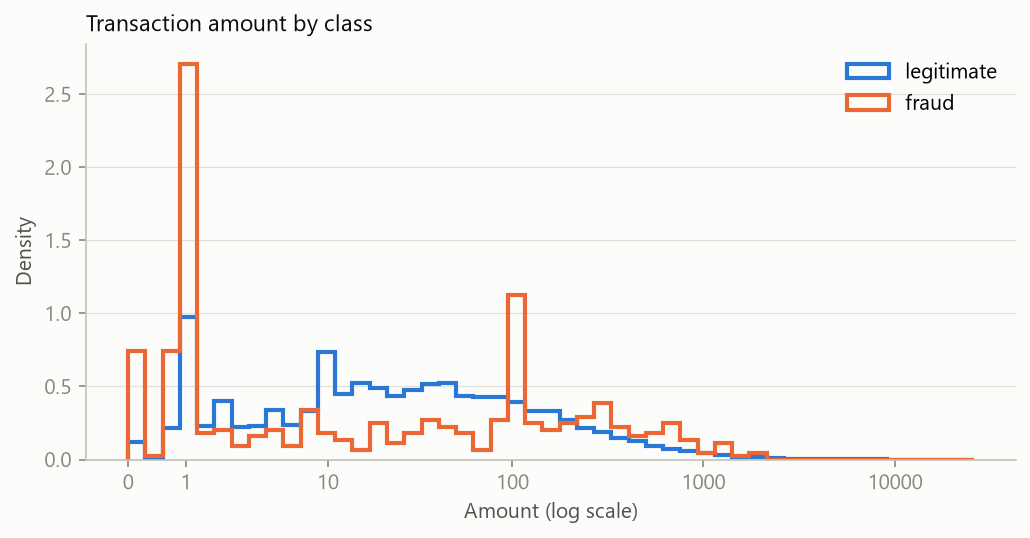

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.6))
log_amount = np.log10(raw["Amount"] + 1)  # +1 keeps zero amounts on the axis
bins = np.linspace(0, log_amount.max(), 50)
for cls, color, label in [(0, LEGIT, "legitimate"), (1, FRAUD, "fraud")]:
    ax.hist(log_amount[raw["Class"] == cls], bins=bins, density=True,
            histtype="step", linewidth=2, color=color, label=label)
ticks = [0, 1, 10, 100, 1000, 10000]
ax.set_xticks(np.log10(np.array(ticks) + 1), [str(t) for t in ticks])
ax.set_xlabel("Amount (log scale)")
ax.set_ylabel("Density")
ax.set_title("Transaction amount by class", loc="left")
ax.legend()
plt.show()

**Interpretation**

- Fraud amounts are **not** simply larger: the median fraud is **9.25** against **22.00** for
  legitimate transactions.
- Fraud splits into two groups. **36.8% of frauds are for 1 or less** (5.5% are exactly 0), against
  10.7% of legitimate transactions: the typical "card-testing" pattern, where small charges check
  that a stolen card works. Fraud also has a heavier large-amount tail (**7.1% above 500** vs 3.2%).
- `Amount` therefore carries some signal but can't separate the classes alone, and its scale
  (0 to 25,691) is very different from the V features, which is why logistic regression is
  trained on standardised features.

## 4. Activity and fraud over time

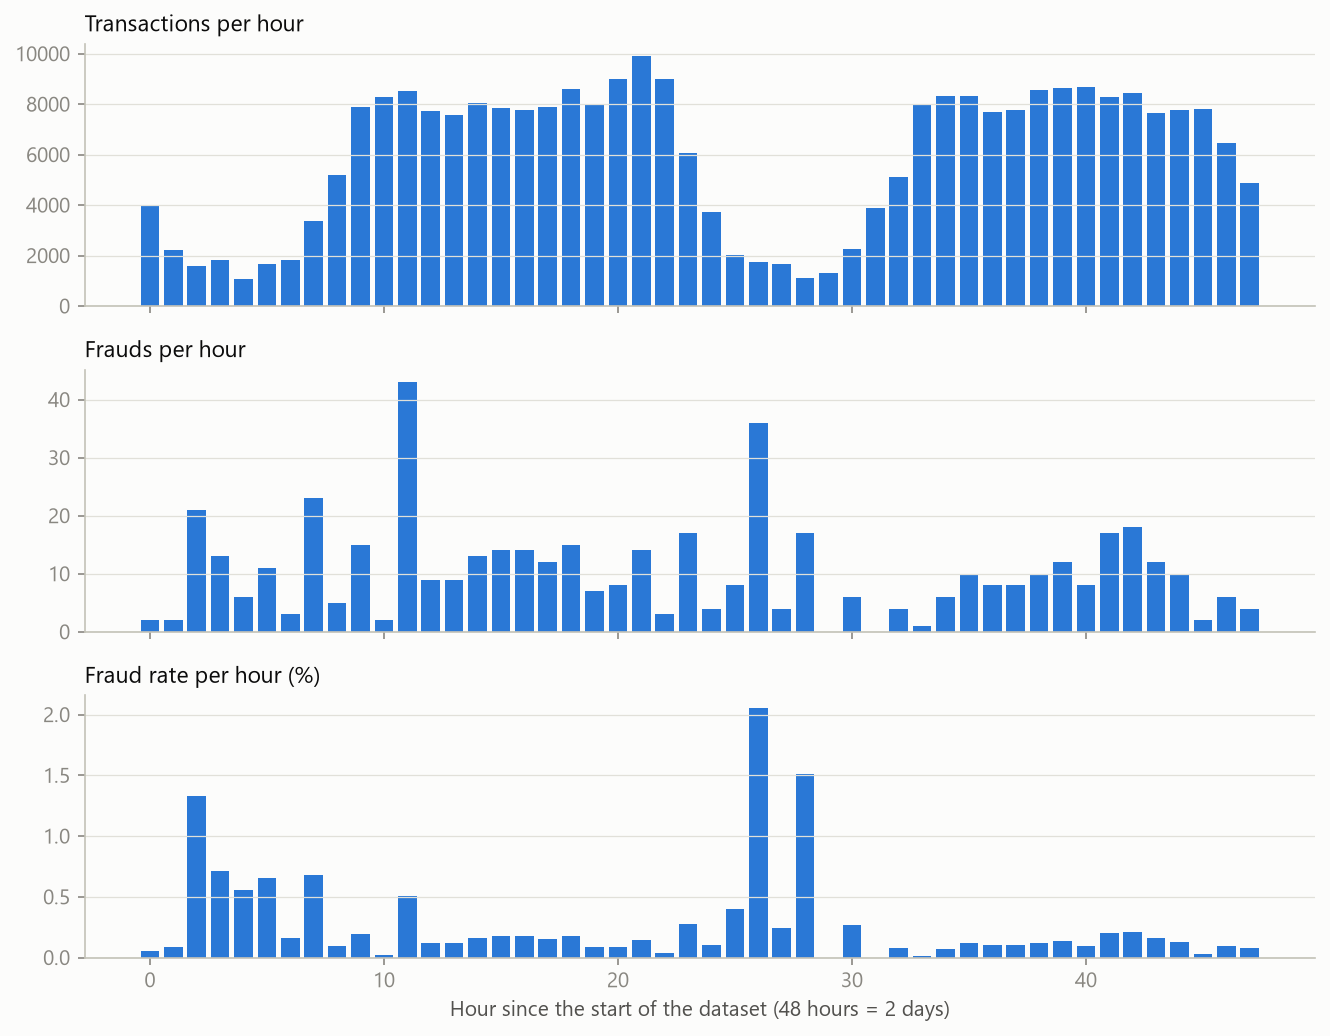

In [9]:
hourly = raw.assign(hour=(raw["Time"] // 3600).astype(int)).groupby("hour").agg(
    transactions=("Class", "size"), frauds=("Class", "sum"))
hourly["fraud_rate_pct"] = 100 * hourly["frauds"] / hourly["transactions"]

fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True)
for ax, col, label in zip(axes, ["transactions", "frauds", "fraud_rate_pct"],
                          ["Transactions per hour", "Frauds per hour", "Fraud rate per hour (%)"]):
    ax.bar(hourly.index, hourly[col], color=SINGLE_SERIES, width=0.8)
    ax.set_title(label, loc="left")
axes[-1].set_xlabel("Hour since the start of the dataset (48 hours = 2 days)")
fig.tight_layout()
plt.show()

In [10]:
day = np.where(hourly.index < 24, "day 1", "day 2")
by_day = hourly.groupby(day)[["transactions", "frauds"]].sum()
by_day["fraud_rate_pct"] = 100 * by_day["frauds"] / by_day["transactions"]
# the dataset doesn't state the clock time of hour 0; hours 0-7 and 24-31 are the visibly quiet
# periods in the chart above (most likely night-time)
quiet = hourly.index % 24 < 7
by_period = hourly.groupby(np.where(quiet, "quiet hours (0-7, 24-31)", "busy hours"))[["transactions", "frauds"]].sum()
by_period["fraud_rate_pct"] = 100 * by_period["frauds"] / by_period["transactions"]
by_period["share_of_all_frauds_pct"] = 100 * by_period["frauds"] / by_period["frauds"].sum()
pd.concat({"by day": by_day, "by activity level": by_period}).round(3)

transactions  ...  share_of_all_frauds_pct
by day            day 1                           144786  ...                      NaN
                  day 2                           140021  ...                      NaN
by activity level busy hours                      256772  ...                   72.967
                  quiet hours (0-7, 24-31)         28035  ...                   27.033

[4 rows x 4 columns]

**Interpretation**

- Activity follows a clear **daily cycle**: two busy periods separated by quiet hours (hours 0–7
  and 24–31 of the stream, most likely night-time; the dataset doesn't state the clock time).
- Fraud is concentrated in the quiet hours: they hold **9.8% of transactions but 27% of frauds**
  (fraud rate 0.474% vs 0.140%, about 3.4× higher). Short spikes (e.g. hours 2, 26 and 28) dominate
  the per-hour fraud rate.
- Day 1 and day 2 look much alike (fraud rate 0.194% vs 0.151%). **Two days is too short for fraud
  tactics to change**, so ULB has little natural concept drift. That is why, on the raw data, the
  ADWIN detector never fired and a frozen random forest stayed strong. To study drift (objectives 2
  and 3) we inject a known one (section 6); IEEE-CIS (6 months) is the optional natural-drift source.

## 5. Which features separate fraud?

Signed correlations: {'V17': -0.326, 'V14': -0.303, 'V12': -0.261, 'V10': -0.217, 'V16': -0.197, 'V3': -0.193, 'V7': -0.187, 'V11': 0.155, 'V4': 0.133, 'V18': -0.111}
Weakest 4: {'V22': 0.0008, 'V23': 0.0027, 'V25': 0.0033, 'V15': 0.0042}


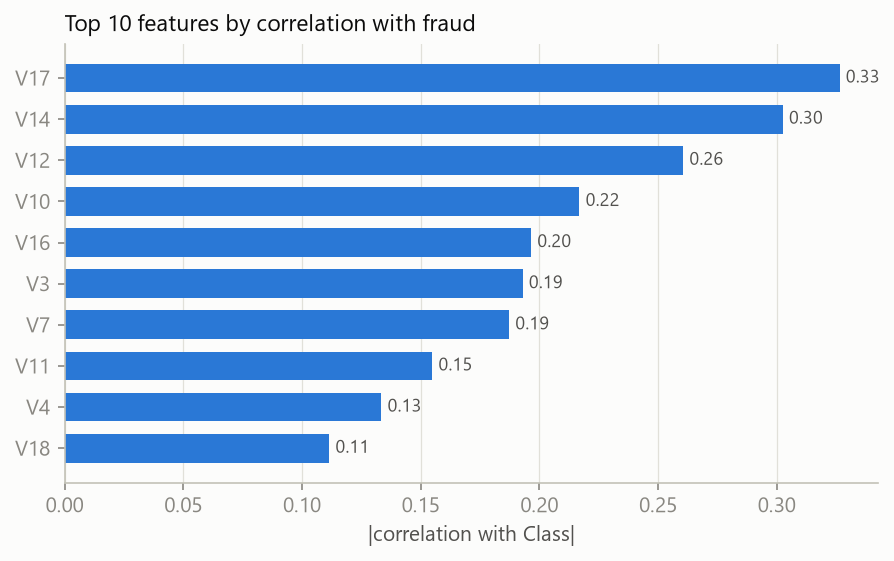

In [11]:
corr = df[features].corrwith(df["Class"])
top = corr.abs().sort_values(ascending=False).head(10)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.set_axisbelow(True)
ax.barh(top.index[::-1], top.values[::-1], color=SINGLE_SERIES, height=0.7)
for y, v in enumerate(top.values[::-1]):
    ax.annotate(f"{v:.2f}", (v, y), xytext=(3, 0), textcoords="offset points", va="center",
                fontsize=8.5, color=INK_SECONDARY)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlabel("|correlation with Class|")
ax.set_title("Top 10 features by correlation with fraud", loc="left")
plt.show()

print("Signed correlations:", corr[top.index].round(3).to_dict())
print("Weakest 4:", corr.abs().sort_values().head(4).round(4).to_dict())

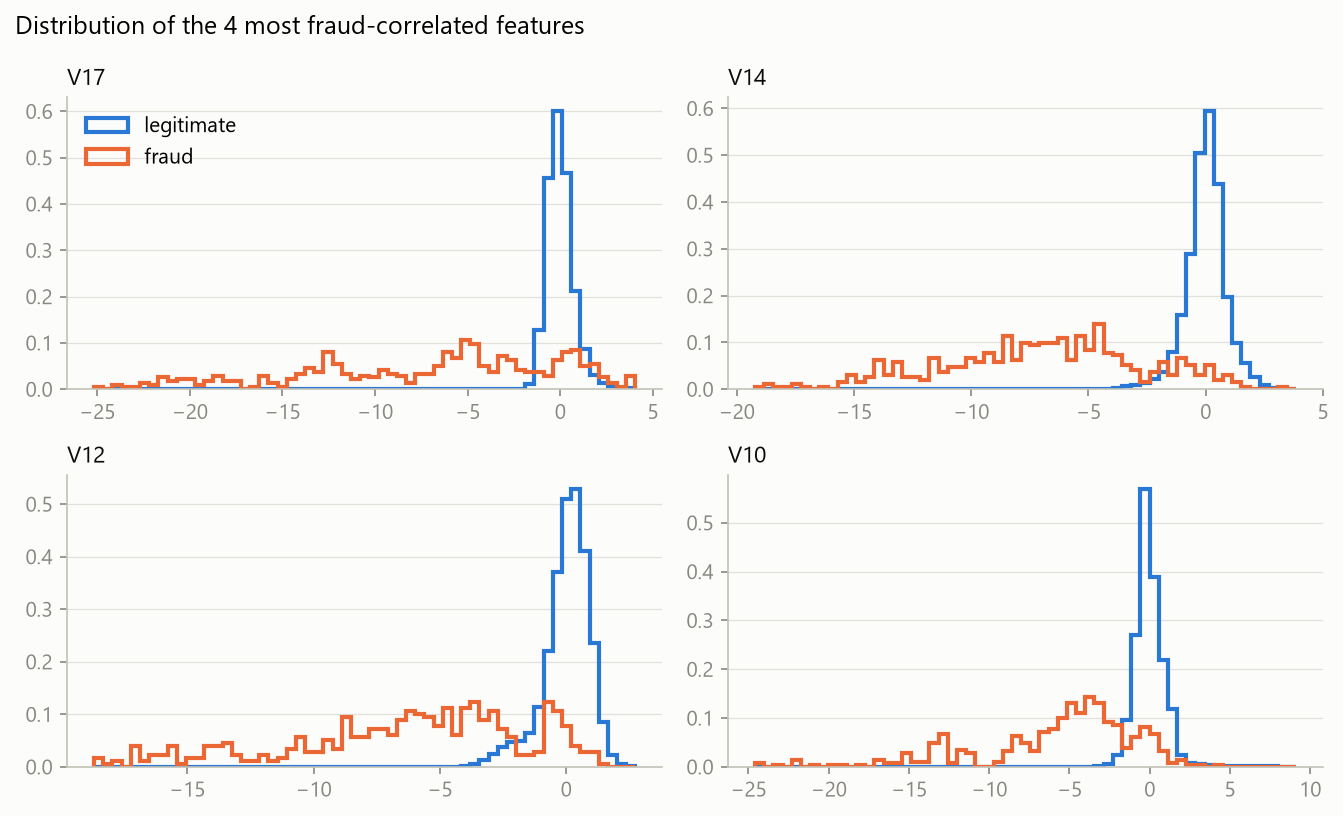

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(9, 5.5))
for ax, feat in zip(axes.flat, top.index[:4]):
    lo, hi = df[feat].quantile([0.001, 0.999])
    bins = np.linspace(min(lo, df.loc[df["Class"] == 1, feat].min()), hi, 60)
    for cls, color, label in [(0, LEGIT, "legitimate"), (1, FRAUD, "fraud")]:
        ax.hist(df.loc[df["Class"] == cls, feat], bins=bins, density=True,
                histtype="step", linewidth=2, color=color, label=label)
    ax.set_title(feat, loc="left")
axes[0, 0].legend()
fig.suptitle("Distribution of the 4 most fraud-correlated features", x=0.01, ha="left")
fig.tight_layout()
plt.show()

**Interpretation**

- The strongest individual signals are **V17, V14, V12 and V10** (|correlation| 0.22–0.33), all
  negative: legitimate transactions sit in a narrow peak around 0, while frauds spread far into
  negative values (down to about −25).
- The weakest are **V22, V23, V25 and V15** (|correlation| below 0.005), essentially no linear
  signal.
- Correlation only captures *linear*, one-feature-at-a-time relationships; tree models (random
  forest, gradient boosting) can also use non-linear combinations, which is one reason they
  outperform logistic regression in the experiments.
- These two lists define the injected drift in the next section.

## 6. The injected drift

ULB covers only 48 hours, so it has little natural drift (section 4). For the controlled experiment we
inject one with `inject_feature_swap`: from the halfway point on, the 4 features most correlated with
fraud swap values with the 4 least correlated. The transactions stay real, but the place where fraud
"shows up" moves.

In [13]:
drifted, pairs = inject_feature_swap(df, at=0.5)
half = len(df) // 2
print("Swapped pairs:", pairs)
print(f"Drift starts at row {half:,} (hour {df['Time'].iloc[half] / 3600:.1f})")

fraud = drifted["Class"] == 1
before, after = fraud & (drifted.index < half), fraud & (drifted.index >= half)
pd.DataFrame({
    "fraud mean, before drift": drifted.loc[before, [a for a, _ in pairs] + [b for _, b in pairs]].mean(),
    "fraud mean, after drift": drifted.loc[after, [a for a, _ in pairs] + [b for _, b in pairs]].mean(),
    "legitimate mean (whole stream)": drifted.loc[~fraud, [a for a, _ in pairs] + [b for _, b in pairs]].mean(),
}).round(2)

Swapped pairs: [('V17', 'V22'), ('V14', 'V23'), ('V12', 'V25'), ('V10', 'V15')]
Drift starts at row 142,403 (hour 23.5)


,"fraud mean, before drift","fraud mean, after drift",legitimate mean (whole stream)
V17,-7.51,0.41,0.09
V14,-7.26,0.06,0.04
V12,-6.46,-0.16,-0.04
V10,-5.75,-0.47,-0.12
V22,-0.32,-5.64,-0.08
V23,-0.12,-6.62,-0.03
V25,0.21,-6.02,0.05
V15,0.22,-5.59,0.13


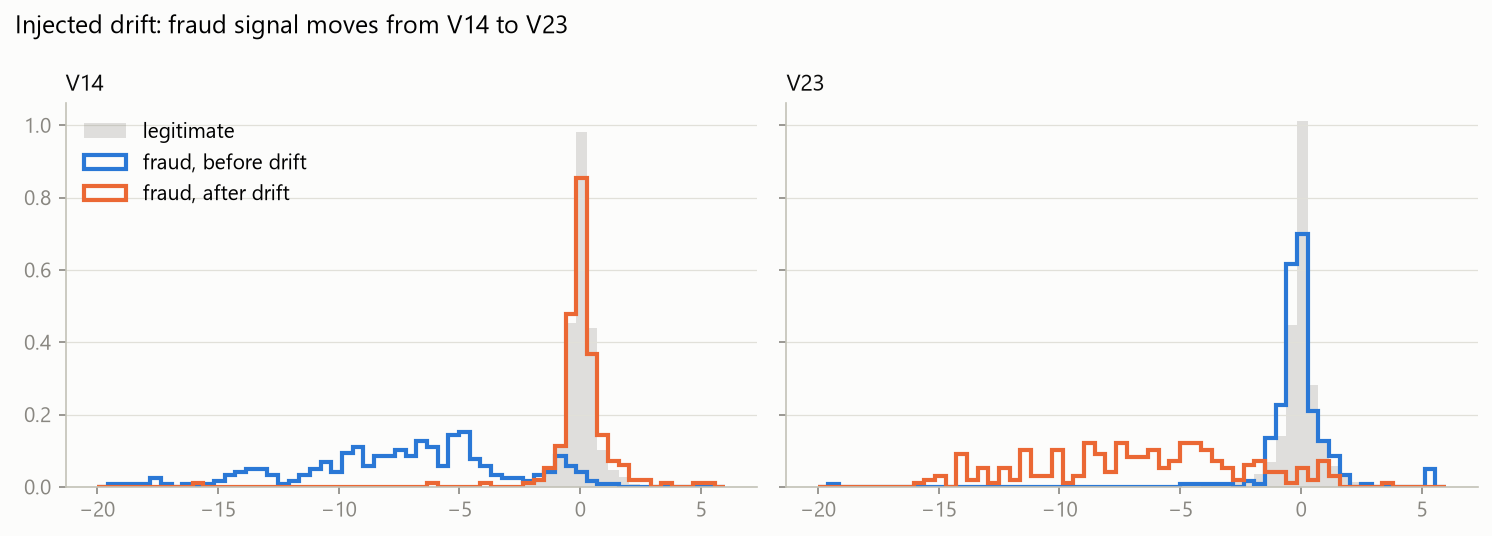

In [14]:
strong, weak = pairs[1]  # V14 <-> V23
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
bins = np.linspace(-20, 6, 60)
for ax, feat in zip(axes, [strong, weak]):
    ax.hist(drifted.loc[~fraud, feat].clip(-20, 6), bins=bins, density=True, histtype="stepfilled",
            color=MUTED, alpha=0.25, label="legitimate")
    ax.hist(drifted.loc[before, feat].clip(-20, 6), bins=bins, density=True, histtype="step",
            linewidth=2, color=LEGIT, label="fraud, before drift")
    ax.hist(drifted.loc[after, feat].clip(-20, 6), bins=bins, density=True, histtype="step",
            linewidth=2, color=FRAUD, label="fraud, after drift")
    ax.set_title(feat, loc="left")
axes[0].legend()
fig.suptitle(f"Injected drift: fraud signal moves from {strong} to {weak}", x=0.01, ha="left")
fig.tight_layout()
plt.show()

**Interpretation**

- From row 142,403 (hour 23.5) on, each strong feature swaps values with a weak one:
  V17↔V22, V14↔V23, V12↔V25, V10↔V15.
- Before the drift, fraud shows up as very low **V14** (mean −7.26) while V23 is near 0 (−0.12).
  After it, fraud shows up in **V23** (−6.62) while V14 looks normal (0.06). The same happens for
  the other three pairs.
- Legitimate transactions are centred near 0 in all eight features, so they look much the same
  before and after. What changes is **where fraud appears**: a change in P(fraud | features),
  i.e. genuine *concept* drift.
- Consequence: a model trained before the drift keeps looking at V14, V17, V12 and V10, which no
  longer reveal fraud. That is exactly the failure a frozen model shows after the drift in the
  experiments.

## 7. How large should evaluation batches be?

In [15]:
rows = []
for size in [2000, 5000, 10000, 20000]:
    per_batch = df["Class"].groupby(np.arange(len(df)) // size).sum()
    rows.append({"batch size": size, "batches": len(per_batch),
                 "frauds per batch (median)": per_batch.median(), "min": per_batch.min(),
                 "batches with < 5 frauds (%)": round(100 * (per_batch < 5).mean(), 1),
                 "batches with no fraud": int((per_batch == 0).sum())})
pd.DataFrame(rows).set_index("batch size")

,batches,frauds per batch (median),min,batches with < 5 frauds (%),batches with no fraud
batch size,,,,,
2000,143,2.0,0,76.2,25
5000,57,6.0,1,36.8,0
10000,29,13.0,3,13.8,0
20000,15,24.0,4,6.7,0


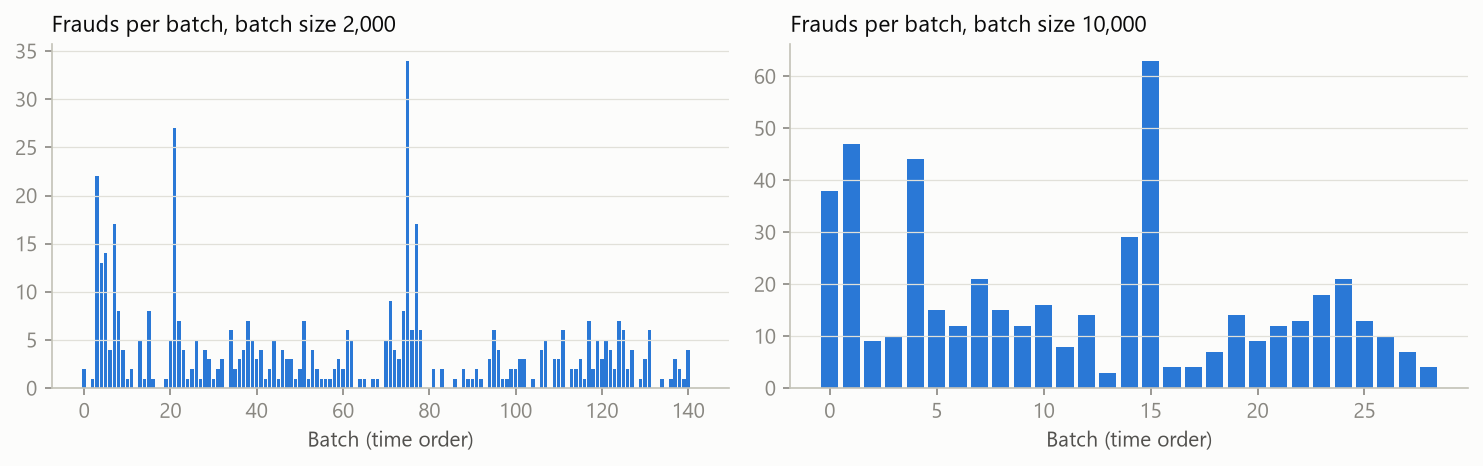

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, size in zip(axes, [2000, 10000]):
    per_batch = df["Class"].groupby(np.arange(len(df)) // size).sum()
    ax.bar(per_batch.index, per_batch.values, color=SINGLE_SERIES, width=0.8)
    ax.set_title(f"Frauds per batch, batch size {size:,}", loc="left")
    ax.set_xlabel("Batch (time order)")
fig.tight_layout()
plt.show()

**Interpretation**

The models are scored batch by batch, and PR-AUC needs at least one fraud in a batch (and several
for a stable value).

| Batch size | Batches | Median frauds/batch | Batches with < 5 frauds | Batches with no fraud |
|---|---|---|---|---|
| 2,000 | 143 | 2 | 76% | 25 |
| 5,000 | 57 | 6 | 37% | 0 |
| **10,000** | **29** | **13** | **14%** | **0** |
| 20,000 | 15 | 24 | 7% | 0 |

At 2,000, a quarter of the batches contain no fraud at all and most hold fewer than 5, so their
scores are mostly noise. **10,000** gives a median of 13 frauds per batch, never fewer than 3, while
keeping 29 points in time to watch performance change. This is the batch size used for every ULB
experiment. Fraud also arrives unevenly (batch 15 alone holds 63 frauds), so per-batch scores
remain somewhat noisy, which is why the over-time plots use a 3-batch rolling mean.

## 8. The synthetic drifting stream

Built in `src/data/synthetic.py` so the pipeline could be developed and tested before any download,
on data where the drift is known exactly.

In [17]:
syn = load_dataset(seed=42)  # 50,000 rows, 1% fraud, drift at the halfway point
h = len(syn) // 2
syn_fraud = syn["Class"] == 1
print(f"{len(syn):,} rows, fraud rate {syn['Class'].mean():.4f}")
pd.DataFrame({
    "fraud mean, first half": syn.loc[syn_fraud & (syn.index < h), ["V1", "V2", "V3", "V4", "V5", "V6"]].mean(),
    "fraud mean, second half": syn.loc[syn_fraud & (syn.index >= h), ["V1", "V2", "V3", "V4", "V5", "V6"]].mean(),
    "legitimate mean": syn.loc[~syn_fraud, ["V1", "V2", "V3", "V4", "V5", "V6"]].mean(),
}).round(2)

50,000 rows, fraud rate 0.0105


,"fraud mean, first half","fraud mean, second half",legitimate mean
V1,1.93,0.08,0.00
V2,2.04,0.02,-0.00
V3,2.04,-0.06,0.01
V4,0.06,-2.08,-0.01
V5,0.02,-2.02,-0.00
V6,-0.06,-1.99,-0.00


**Interpretation**

The synthetic stream (50,000 transactions, 1% fraud) has a known, abrupt drift at the halfway
point. In the first half, fraud is shifted up by about +2 on **V1–V3**; in the second half, those
look legitimate and fraud is shifted down by about −2 on **V4–V6** instead. Legitimate
transactions stay at 0 throughout. Because the truth is known exactly, it was used to develop and
test the whole pipeline (detectors must flag the halfway point; frozen models must fail after it)
before the real data was used.

## 9. Summary: what the EDA means for the models

| Finding | Consequence in the project |
|---|---|
| Fraud is 0.173% of transactions (1 in 578) | Accuracy is useless: we report PR-AUC, recall at 90% precision and FPR; we compare class weights, SMOTE and undersampling |
| Data is clean and already time-ordered | Light preparation only; transactions are streamed in time order and never shuffled |
| `Time` only describes position in this 48-hour file | Used for ordering, never as a feature |
| `Amount` differs by class (card testing ≤ 1, heavier tail) but overlaps a lot | Kept as a feature; standardised for logistic regression |
| V17, V14, V12, V10 carry the strongest signal; V22, V23, V25, V15 almost none | Defines the injected drift (strong ↔ weak swap) |
| Two days show no clear change in fraud behaviour | Raw ULB has little natural drift, so we inject a known drift; IEEE-CIS is the optional natural-drift dataset |
| Fraud arrives unevenly; small batches often contain no fraud | Batch size 10,000 for ULB (median 13 frauds per batch); 3-batch smoothing in plots |
| Synthetic stream has a known drift on known features | Used to verify every component before the real data |